In [1]:
import serial
import time
import csv
import struct

PORT = 'COM6'
BAUD = 1000000      # match Arduino
DURATION = 0.1 * 60
OUTPUT = "arduino_log.csv"

# Must match the Arduino packet layout exactly:
# 1 sync byte (0xAA) + 4 byte little-endian timestamp_us + 2 byte little-endian
# raw value + 1 XOR checksum byte over the 6 payload bytes.
SYNC_BYTE = 0xAA
PAYLOAD_FMT = '<IH'
PAYLOAD_SIZE = struct.calcsize(PAYLOAD_FMT)     # 6 bytes
PACKET_SIZE = 1 + PAYLOAD_SIZE + 1              # sync + payload + checksum = 8 bytes

n_bad_checksum = [0]   # simple mutable counter shared with read_packet()

def checksum_ok(payload_bytes, checksum_byte):
    calc = 0
    for b in payload_bytes:
        calc ^= b
    return calc == checksum_byte

def read_packet(buf):
    """
    Pull one framed, checksum-validated packet out of a persistent
    bytearray buffer, with proper backtracking.

    The sync byte (0xAA) is not escaped, so it can occasionally occur
    naturally inside a timestamp or ADC value. If we lock onto such a
    byte by mistake and it fails the checksum, we must discard only
    THAT ONE byte and keep scanning -- not the whole packet-sized chunk
    -- otherwise the real sync byte sitting a few bytes later gets
    thrown away too and the stream never re-synchronizes.

    Returns (timestamp_us, raw) for one packet, or None if the buffer
    doesn't yet contain a complete valid packet (caller should read
    more bytes and try again).
    """
    while True:
        idx = buf.find(bytes([SYNC_BYTE]))
        if idx == -1:
            # No candidate sync byte at all; avoid unbounded growth
            # while we wait for one to arrive.
            if len(buf) > 4096:
                del buf[:-1]
            return None

        if len(buf) - idx < PACKET_SIZE:
            return None   # not enough bytes yet for this candidate

        candidate = buf[idx: idx + PACKET_SIZE]
        payload = candidate[1: 1 + PAYLOAD_SIZE]
        checksum_byte = candidate[1 + PAYLOAD_SIZE]

        if checksum_ok(payload, checksum_byte):
            timestamp_us, raw = struct.unpack(PAYLOAD_FMT, bytes(payload))
            del buf[: idx + PACKET_SIZE]   # consume packet (and any junk before it)
            return timestamp_us, raw
        else:
            del buf[: idx + 1]             # false sync lock: drop just this byte, retry
            n_bad_checksum[0] += 1

def sampling():
    with serial.Serial(PORT, BAUD, timeout=0.1) as ser, open(OUTPUT, "w", newline="") as f:
        ser.reset_input_buffer()

        writer = csv.writer(f, delimiter=';')
        writer.writerow(["timestamp_us", "adc"])

        start = time.time()
        i = 0
        buffer_rows = []
        buf = bytearray()

        while time.time() - start < DURATION:
            chunk = ser.read(256)
            if chunk:
                buf.extend(chunk)

            while True:
                packet = read_packet(buf)
                if packet is None:
                    break
                timestamp_us, val = packet
                buffer_rows.append([timestamp_us, val])
                i += 1

                if len(buffer_rows) >= 1000:
                    writer.writerows(buffer_rows)
                    buffer_rows = []

        # write leftovers
        if buffer_rows:
            writer.writerows(buffer_rows)

        elapsed = time.time() - start
        sampling_rate = i / elapsed

        print(f"Samples: {i}")
        print(f"Rejected/misaligned bytes: {n_bad_checksum[0]}")
        print(f"Elapsed: {elapsed:.3f}s")
        print(f"Rate: {sampling_rate:.1f} Hz")

    return sampling_rate

if __name__ == "__main__":
    sampling_rate = sampling()


Samples: 22912
Rejected/misaligned bytes: 0
Elapsed: 6.004s
Rate: 3816.1 Hz


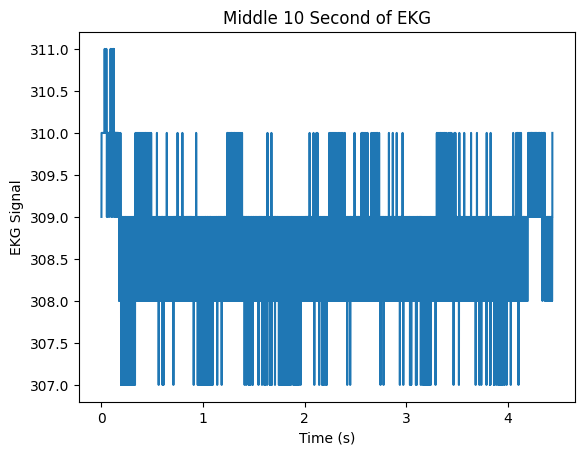

In [2]:
import pandas as pd
import numpy as np
dfRad = pd.read_csv('arduino_log.csv', sep = ';', header = 0, names = ['timestamp_us', 'EKG'])

#show the signal in the correct time frame
import matplotlib.pyplot as plt
# Compute time vector directly from the Arduino microsecond timestamps
# (more accurate than dividing by the average sampling_rate),
# using the unwrapped timestamps so a micros() overflow doesn't corrupt it
time = (dfRad['timestamp_us'] - dfRad['timestamp_us'].iloc[0]) / 1e6

mid_time = time.iloc[len(time) // 2]
# Select the 10-second window around the center
mask = (time >= mid_time - 5) & (time <= mid_time + 5)

# Plot
plt.plot(time[mask], dfRad['EKG'][mask])
#plt.ylim(0, 5)             # limit y-axis to 5
plt.xlabel('Time (s)')
plt.ylabel('EKG Signal')
plt.title('Middle 10 Second of EKG')
plt.show()


In [4]:
# Diagnostic: check how consistently the Arduino actually sampled,
# using the per-sample microsecond timestamps (independent of the PC-side
# read loop, so this reflects true hardware timing, not Python overhead).
# Uses the unwrapped timestamps, so this stays correct even across a
# micros() overflow (~every 71.6 minutes).
dt_us = pd.Series(dfRad['timestamp_us']).diff().dropna()   # interval between samples, in microseconds
dt_ms = dt_us / 1000.0

print(f"Samples analyzed: {len(dt_us)}")
print(f"Mean interval:    {dt_ms.mean():.3f} ms  ->  {1000/dt_ms.mean():.1f} Hz average")
print(f"Median interval:  {dt_ms.median():.3f} ms")
print(f"Std deviation:    {dt_ms.std():.3f} ms")
print(f"Min / Max:        {dt_ms.min():.3f} ms / {dt_ms.max():.3f} ms")
#print in frequency
print(f"Min / Max frequency: {1000/dt_ms.max():.1f} Hz / {1000/dt_ms.min():.1f} Hz")


Samples analyzed: 22911
Mean interval:    0.194 ms  ->  5158.8 Hz average
Median interval:  0.192 ms
Std deviation:    0.003 ms
Min / Max:        0.192 ms / 0.204 ms
Min / Max frequency: 4902.0 Hz / 5208.3 Hz
